<a href="https://colab.research.google.com/github/SAMBOAH95/Machine-Learning-Projects/blob/main/Task-1-Student-Score-Prediction/Student_Score_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import tools for machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [7]:

# Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:

import pandas as pd

file_path = '/content/drive/MyDrive/Elevo/Task 1/StudentPerformanceFactors.csv'

df = pd.read_csv(file_path)

# Display the first five rows
df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [9]:
# Check the first five rows
display(df.head())

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [10]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)


Dataset shape: (6607, 20)


In [11]:
# Check column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [12]:
# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [13]:

# Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Count all missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Inspect the columns we need
print("\nRequired columns:")
print(df[['Hours_Studied', 'Exam_Score']].head())

# Check their data types
print("\nData types:")
print(df[['Hours_Studied', 'Exam_Score']].dtypes)


Missing values per column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Total missing values: 235
Duplicate rows: 0

Required columns:
   Hours_Studied  Exam_Score
0             23          67
1             19          61
2             24          74
3             29          71
4             19          70

Data types:
Hours_Studied    int64
Exam_Score       int64
dty

In [14]:

# Select the variables needed for Student Score Prediction

data = df[['Hours_Studied', 'Exam_Score']].copy()

# Display the first five rows
display(data.head())


,Hours_Studied,Exam_Score
0,23,67
1,19,61
2,24,74
3,29,71
4,19,70


In [15]:

# Generate descriptive statistics for our selected variables

data.describe()


,Hours_Studied,Exam_Score
count,6607.000000,6607.000000
mean,19.975329,67.235659
std,5.990594,3.890456
min,1.000000,55.000000
25%,16.000000,65.000000
50%,20.000000,67.000000
75%,24.000000,69.000000
max,44.000000,101.000000


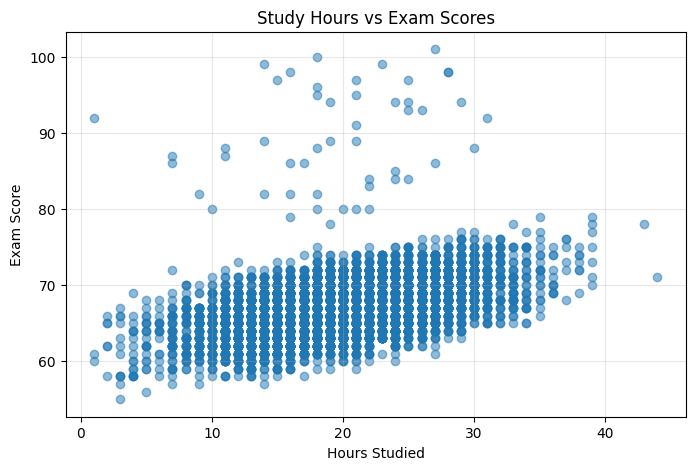

In [16]:

# Create a scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(
    data['Hours_Studied'],
    data['Exam_Score'],
    alpha=0.5
)

plt.title('Study Hours vs Exam Scores')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.grid(True, alpha=0.3)

plt.show()


In [17]:

# Calculate the correlation between study hours and exam scores

correlation = data['Hours_Studied'].corr(data['Exam_Score'])

print("Correlation coefficient:", round(correlation, 3))


Correlation coefficient: 0.445


In [18]:

from sklearn.model_selection import train_test_split

# Define input feature (X) and target variable (y)
X = data[['Hours_Studied']]
y = data['Exam_Score']

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 5285
Testing records: 1322


In [19]:

from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [20]:

# Display the model's learned parameters

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print(
    f"\nRegression Equation:\n"
    f"Exam_Score = {model.intercept_:.3f} "
    f"+ ({model.coef_[0]:.3f} × Hours_Studied)"
)


Intercept: 61.51116746904424
Coefficient: 0.285668744443087

Regression Equation:
Exam_Score = 61.511 + (0.286 × Hours_Studied)


In [21]:

# Predict exam scores using the testing data

y_pred = model.predict(X_test)

# Display actual and predicted scores for the first 10 students
results = pd.DataFrame({
    'Hours_Studied': X_test['Hours_Studied'].values,
    'Actual_Score': y_test.values,
    'Predicted_Score': y_pred
})

display(results.head(10))


,Hours_Studied,Actual_Score,Predicted_Score
0,20,65,67.224542
1,22,65,67.795880
2,21,71,67.510211
3,12,64,64.939192
4,21,66,67.510211
5,21,66,67.510211
6,37,72,72.080911
7,24,66,68.367217
8,17,70,66.367536
9,16,70,66.081867


In [22]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Mean Squared Error (MSE): {mse:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R-squared (R²): {r2:.3f}")


Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 2.448
Mean Squared Error (MSE): 10.856
Root Mean Squared Error (RMSE): 3.295
R-squared (R²): 0.232


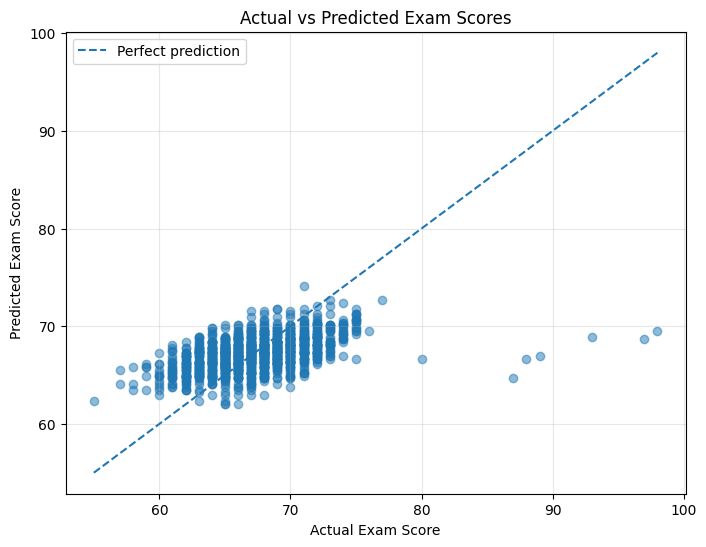

In [23]:

# Plot actual scores against predicted scores

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Reference line representing perfect predictions
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle='--',
    label='Perfect prediction'
)

plt.title('Actual vs Predicted Exam Scores')
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [24]:

# Predict the exam score of a student who studies for 6 hours

new_student = pd.DataFrame({
    'Hours_Studied': [6]
})

predicted_score = model.predict(new_student)[0]

print("Study hours:", 6)
print(f"Predicted exam score: {predicted_score:.2f}")


Study hours: 6
Predicted exam score: 63.23
